# Lab 12.4: Stickers on Rejected Parts (the Chapter 12 case study)

Chapter 12, Concepts Inside Networks. Run-only notebook. Total run time about 5 minutes on a laptop CPU, plus a one-time download of about 130 MB.

**Data.** The Candle subset of the VisA (Visual Anomaly) dataset, Zou et al. (2022), ECCV 2022: 1,000 normal and 100 anomalous color photographs of several candles per image, with pixel masks of the defects. The candles are real; the paper states that the defects were made by hand to look realistic. License: CC BY 4.0 (commercial use and adaptations allowed; attribution required). Source and license: https://github.com/amazon-science/spot-diff

**Scenario (planted, and said so).** Imagine that inspectors put a small white label on parts they reject, and that the photos used for training were taken after the labels went on. We simulate this: on half of the defective training tiles we paste a 9 by 9 pixel white label with a dark edge (the "sticker"). We train one network on these images and one on clean images, then ask what a behavioral test, TCAV and an intervention reveal. The sticker is our addition; the candles, defects and masks come from the dataset.

In [1]:
import os, glob, tarfile, urllib.request, pathlib
import numpy as np, torch, torch.nn as nn
from PIL import Image
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
torch.set_num_threads(4)
CACHE = pathlib.Path(os.environ.get("XAI_DATA", "data")) / "VisA"     # set XAI_DATA to reuse a download
ROOT = CACHE / "candle"
URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
if not (ROOT / "image_anno.csv").exists():
    # The archive is an uncompressed tar whose first folder is candle/: stream it, keep that folder, stop.
    CACHE.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(URL) as r, tarfile.open(fileobj=r, mode="r|") as tf:
        for m in tf:
            if m.name.split("/")[0] != "candle":
                if ROOT.exists(): break
                continue
            if m.isfile() and ".." not in m.name and not m.name.startswith("/"):
                tf.extract(m, CACHE, set_attrs=False)
DATA = ROOT / "Data"
print("normal images:", len(glob.glob(str(DATA / "Images" / "Normal" / "*.JPG"))),
      " anomalous images:", len(glob.glob(str(DATA / "Images" / "Anomaly" / "*.JPG"))),
      " masks:", len(glob.glob(str(DATA / "Masks" / "Anomaly" / "*.png"))))

normal images: 1000  anomalous images: 100  masks: 100


## 1. Cut the images into tiles

Each image is converted to grayscale, scaled to 30 percent and cut into 64 x 64 tiles with a stride of 32. Every tile of an anomalous image is kept; from each normal image we keep 10 random tiles, to save memory. A tile is *defective* if at least 20 of its pixels are in the defect mask; tiles that touch a defect with fewer pixels are left out as ambiguous. The split is by image, so tiles of one photograph never appear in both training and test (Chapter 3): normal images 0 to 599 and anomalous images 0 to 49 train the models, normal 600 to 799 and anomalous 50 to 74 test them, and the rest supply the concept examples.

In [2]:
rng = np.random.default_rng(0)
X, Y, G, K = [], [], [], []                     # G: image number, K: 1 if the tile comes from an anomalous image
for kind, d in ((0, "Normal"), (1, "Anomaly")):
    for f in sorted(glob.glob(str(DATA / "Images" / d / "*.JPG"))):
        idx = int(os.path.basename(f).split(".")[0])
        im = Image.open(f).convert("L"); w, h = int(im.size[0] * 0.3), int(im.size[1] * 0.3)
        a = np.asarray(im.resize((w, h), Image.BILINEAR), dtype=np.uint8)
        m = (np.asarray(Image.open(DATA / "Masks" / d / ("%03d.png" % idx)).resize((w, h), Image.NEAREST)) > 0
             if kind else np.zeros((h, w), bool))
        pos = [(y, x) for y in range(0, h - 63, 32) for x in range(0, w - 63, 32)]
        if not kind:
            pos = [pos[i] for i in rng.choice(len(pos), 10, replace=False)]
        for y, x in pos:
            area = m[y:y+64, x:x+64].sum()
            if 0 < area < 20: continue
            X.append(a[y:y+64, x:x+64]); Y.append(int(area >= 20)); G.append(idx); K.append(kind)
X = (np.stack(X) / 255.).astype(np.float32); Y, G, K = np.array(Y), np.array(G), np.array(K)
S = np.where(K == 0, np.digitize(G, [600, 800]), np.digitize(G, [50, 75]))   # 0 train, 1 test, 2 concept pool
tr, te, cp = S == 0, S == 1, S == 2
print("all tiles %d, defective %d" % (len(Y), Y.sum()))
for name, s in (("train", tr), ("test", te), ("concept pool", cp)):
    print("%-13s tiles %5d  defective %3d" % (name, s.sum(), Y[s].sum()))

all tiles 19678, defective 542
train         tiles 10861  defective 217
test          tiles  4412  defective 134
concept pool  tiles  4405  defective 191


**Checkpoint 1.** 19,678 tiles, 542 defective: train 10,861 (217), test 4,412 (134), concept pool 4,405 (191).

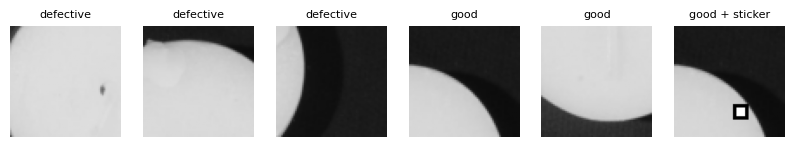

In [3]:
def sticker(img, rng, s=9):
    """A small white label with a dark edge, pasted at a random place."""
    img = img.copy(); y, x = rng.integers(2, img.shape[0] - s - 2, 2)
    img[y:y+s, x:x+s] = 0.0; img[y+2:y+s-2, x+2:x+s-2] = 1.0
    return img

def speck(img, rng, r=2):
    """A small dark disk: a plausible defect cue, such as a speck of dirt in the wax."""
    img = img.copy(); cy, cx = rng.integers(r + 2, img.shape[0] - r - 2, 2)
    yy, xx = np.ogrid[:img.shape[0], :img.shape[1]]
    img[(yy - cy) ** 2 + (xx - cx) ** 2 <= r * r] = 0.0
    return img

r = np.random.default_rng(0); d = np.where(te & (Y == 1))[0][[0, 40, 80]]; g = np.where(te & (Y == 0))[0][[0, 500]]
panels = [(X[i], "defective") for i in d] + [(X[i], "good") for i in g] + [(sticker(X[g[0]], r), "good + sticker")]
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax, (img, t) in zip(axes, panels):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1); ax.set_title(t, fontsize=8); ax.axis("off")
plt.show()

## 2. Train two networks (about 4 minutes)

In [4]:
class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.f1 = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2))
        s.f2 = nn.Sequential(nn.Conv2d(32, 48, 3, padding=1), nn.BatchNorm2d(48), nn.ReLU(), nn.MaxPool2d(2))
        s.head = nn.Sequential(nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(48, 2))
    def forward(s, x): return s.head(s.f2(s.f1(x)))

models = {}
for marked in (True, False):
    r = np.random.default_rng(1)
    idx = np.r_[np.where(tr & (Y == 1))[0], r.choice(np.where(tr & (Y == 0))[0], 1500, replace=False)]
    Xt, Yt = X[idx].copy(), Y[idx].copy()
    if marked:                                       # a label on half of the rejected parts
        for i in np.where(Yt == 1)[0]:
            if r.random() < 0.5: Xt[i] = sticker(Xt[i], r)
    torch.manual_seed(1); np.random.seed(1)
    net = Net(); opt = torch.optim.Adam(net.parameters(), 2e-3)
    xt, yt = torch.tensor(Xt[:, None]), torch.tensor(Yt)
    lossf = nn.CrossEntropyLoss(weight=torch.tensor([1.0, (Yt == 0).sum() / (Yt == 1).sum()], dtype=torch.float32))
    for ep in range(30):
        perm = torch.randperm(len(yt))
        for b in range(0, len(yt), 64):
            j = perm[b:b+64]; xb = xt[j]
            if np.random.rand() < .5: xb = xb.flip(3)
            if np.random.rand() < .5: xb = xb.flip(2)
            opt.zero_grad(); lossf(net(xb), yt[j]).backward(); opt.step()
    models["shortcut" if marked else "clean"] = net.eval()
print("trained:", list(models))

trained: ['shortcut', 'clean']


## 3. Behavioral test: put stickers on good parts

As Winkler et al. (2019) did with surgical ink on benign moles, we paste a sticker on every test tile and compare specificity (the share of good tiles passed) before and after. We also measure the intervention effect: the mean change in the defect logit when a sticker is added.

In [5]:
Xte, Yte = X[te], Y[te]
Xte_s = np.stack([sticker(x, np.random.default_rng(1000 + i)) for i, x in enumerate(Xte)])
def logit(net, A):
    with torch.no_grad(): o = net(torch.tensor(A[:, None])); return (o[:, 1] - o[:, 0]).numpy()
for name, net in models.items():
    l, ls = logit(net, Xte), logit(net, Xte_s)
    print("%-8s AUC %.3f  sensitivity %.2f  specificity %.3f | with stickers: specificity %.3f | "
          "logit change: good %+.1f, defective %+.1f" % (name, roc_auc_score(Yte, l), (l[Yte == 1] > 0).mean(),
          (l[Yte == 0] <= 0).mean(), (ls[Yte == 0] <= 0).mean(), round((ls - l)[Yte == 0].mean(), 1) + 0.0, round((ls - l)[Yte == 1].mean(), 1) + 0.0))

shortcut AUC 0.784  sensitivity 0.18  specificity 0.999 | with stickers: specificity 0.000 | logit change: good +10.0, defective +9.4


clean    AUC 0.822  sensitivity 0.57  specificity 0.865 | with stickers: specificity 0.601 | logit change: good +0.9, defective +0.0


**Checkpoint 2.** Shortcut model: AUC about 0.78, sensitivity about 0.18, specificity about 1.00, falling to 0.00 with stickers; the sticker adds about 10 to the defect logit. Clean model: AUC about 0.82, sensitivity about 0.57, specificity about 0.87, falling to about 0.60 with stickers; the sticker adds about 0.9 on good tiles and nothing on defective ones. These are small models on small, hand-made defects; the point of the lab is the comparison, not the accuracy.

## 4. TCAV at the last convolutional block

Three concepts, 50 examples each, built from concept-pool tiles: *sticker* (good tiles with a pasted label), *dark speck* (the same tiles with a small dark disk) and *defect* (real defective tiles). Twenty random sets of 50 good tiles. Class explained: the 134 defective test tiles. We report the TCAV score (sign) and the mean directional derivative (magnitude).

In [6]:
rc = np.random.default_rng(11)
good, bad = np.where(cp & (Y == 0))[0], np.where(cp & (Y == 1))[0]
pick = rc.choice(good, 50, replace=False)
concepts = {"sticker": np.stack([sticker(X[i], rc) for i in pick]),
            "dark speck": np.stack([speck(X[i], rc) for i in pick]),
            "defect": X[rc.choice(bad, 50, replace=False)]}
rest = np.setdiff1d(good, pick)
randoms = [X[rc.choice(rest, 50, replace=False)] for _ in range(21)]
Xcls = X[te & (Y == 1)]

def acts(net, A):
    with torch.no_grad(): return net.f2(net.f1(torch.tensor(A[:, None]))).reshape(len(A), -1).numpy()
def grads(net, A):
    a = net.f2(net.f1(torch.tensor(A[:, None]))).detach().requires_grad_(True)
    o = net.head(a); (o[:, 1] - o[:, 0]).sum().backward()
    return a.grad.reshape(len(A), -1).numpy()
def cav(A, B):
    Z = np.r_[A, B]; y = np.r_[np.ones(len(A)), np.zeros(len(B))]
    v = LogisticRegression(max_iter=2000).fit(Z, y).coef_[0]; return v / np.linalg.norm(v)

for name, net in models.items():
    g = grads(net, Xcls); R = [acts(net, r) for r in randoms]
    null = [np.mean(g @ cav(R[i], R[(i + 1) % 21]) > 0) for i in range(20)]
    print("%s model: random vs random TCAV %.2f +/- %.2f" % (name, np.mean(null), np.std(null)))
    mags = {}
    for c, A in concepts.items():
        Ac = acts(net, A); ds = [g @ cav(Ac, R[i]) for i in range(20)]
        Sc = [np.mean(d > 0) for d in ds]; mags[c] = np.mean([d.mean() for d in ds])
        print("   %-10s TCAV %.2f +/- %.2f  p = %.1e  magnitude %.4f" % (c, np.mean(Sc), np.std(Sc), stats.ttest_ind(Sc, null).pvalue, mags[c]))
    print("   sticker magnitude relative to defect: %.2f" % (mags["sticker"] / mags["defect"]))

shortcut model: random vs random TCAV 0.49 +/- 0.23


   sticker    TCAV 1.00 +/- 0.00  p = 6.6e-12  magnitude 0.0350


   dark speck TCAV 0.70 +/- 0.17  p = 2.4e-03  magnitude 0.0115


   defect     TCAV 0.73 +/- 0.12  p = 2.1e-04  magnitude 0.0156
   sticker magnitude relative to defect: 2.24


clean model: random vs random TCAV 0.51 +/- 0.15


   sticker    TCAV 0.75 +/- 0.06  p = 1.7e-07  magnitude 0.0133


   dark speck TCAV 0.61 +/- 0.11  p = 3.0e-02  magnitude 0.0070


   defect     TCAV 0.75 +/- 0.05  p = 1.2e-07  magnitude 0.0210
   sticker magnitude relative to defect: 0.63


**Checkpoint 3.** Both models give the sticker a TCAV score far above the random spread (1.00 for the shortcut model and about 0.75 for the clean model), and both pass the t-test easily (p about 7e-12 and 2e-7). A reader of significance alone would say both models use stickers. The magnitudes separate them: relative to the defect concept, the sticker is about 2.2 in the shortcut model and about 0.6 in the clean model. The behavioral test in section 3 separates them most clearly, and it also shows that the clean model is not immune: stickers lower its pass rate on good parts from about 0.87 to about 0.60.

## Questions

1. If you had only run TCAV with the sign score, what would you have concluded about the clean model? Why can the sign score be well above 0.5 for a concept the clean model uses only a little?
2. The dark speck scores 0.70 in the shortcut model and 0.61 in the clean model. With three concepts tested, is either significant after a Bonferroni correction? Is a dark speck a shortcut or a plausible defect cue, and what evidence from the plant would you want?
3. Write the two-sentence finding you would send to the quality manager, and the one test you would add to the model's acceptance checklist.